# 06a — First step: an artificial idle model, and the circuit's effective λ and b_read

**Narrative point 7, first step.** Before realistic idle noise, the arc used Selene's own
error model: a depolarizing Pauli before every native gate, with idling written as explicit
identity operations charged the same rate. It is artificial (ions do not depolarize when
idle, and an Rx(0) has no duration), but it answers a precise question: what λ and b_read
does a real extraction circuit have, compared with the paper's assumed λ = 0.31 and b_read = 1?

**Source:** `python -m qec_timing.studies.effective` → `results/effective/effective.json`.
Selene's native gates mirrored exactly in Stim (`stim_native`), p1 = 5×10⁻⁴ on every
single-qubit gate including Rz, Rzz charged p2 = ρ·p1, readout 2×10⁻³, one idle op per unit
of interval on each data qubit; Z basis. p_data(Δt) and p_read are measured from detection
events at Δt = 1, 2, 4, 8; Eqs. 1–2 make ln(1 − p_data) linear in Δt, giving p_stab and λ.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
ef = json.loads((R / "effective" / "effective.json").read_text())
print(f"{'d':>2}{'rho':>6}{'p_stab':>10}{'lambda':>9}{'b_read':>8}{'floor':>8}")
for e in ef["params"]:
    print(f"{e['d']:>2}{e['rho']:>6g}{e['p_stab']:>10.2e}{e['lam']:>9.3f}{e['b_read']:>8.3f}{e['b_read_floor']:>8.3f}")

 d   rho    p_stab   lambda  b_read   floor
 3     0  2.21e-03    0.150   2.251   1.184
 3     1  3.11e-03    0.106   1.726   1.002
 3     3  4.88e-03    0.068   1.267   0.806
 3    10  1.10e-02    0.030   0.808   0.613
 3    30  2.83e-02    0.011   0.594   0.523
 3   100  8.52e-02    0.003   0.515   0.489
 5     0  2.54e-03    0.131   2.090   1.154
 5     1  3.49e-03    0.095   1.643   0.986
 5     3  5.41e-03    0.061   1.227   0.807
 5    10  1.20e-02    0.027   0.807   0.631
 5    30  3.05e-02    0.011   0.603   0.534
 5   100  9.11e-02    0.002   0.530   0.511
 7     0  2.66e-03    0.125   2.059   1.167
 7     1  3.65e-03    0.090   1.627   1.001
 7     3  5.62e-03    0.059   1.221   0.823
 7    10  1.24e-02    0.026   0.810   0.635
 7    30  3.15e-02    0.010   0.609   0.544
 7   100  9.37e-02    0.003   0.540   0.518


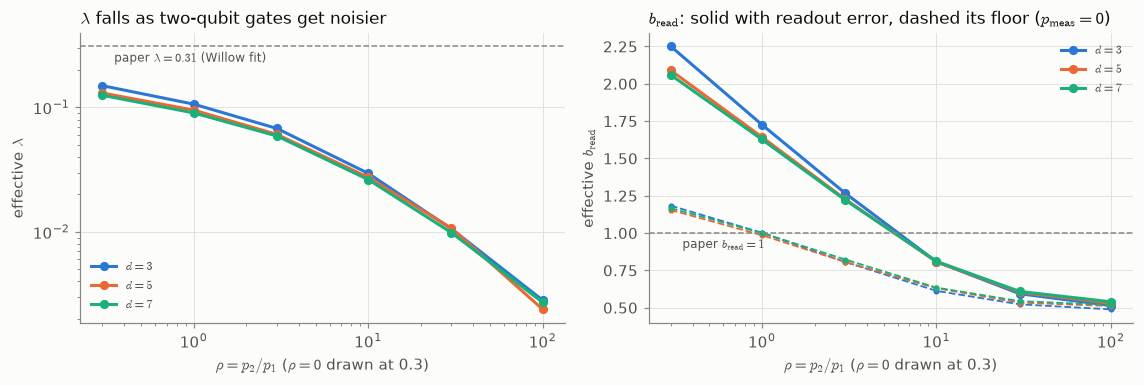

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for d in sorted({e["d"] for e in ef["params"]}):
    rows = [e for e in ef["params"] if e["d"] == d]
    rho = [max(e["rho"], 0.3) for e in rows]
    axes[0].plot(rho, [e["lam"] for e in rows], "o-", color=P.D_COLOR[d], label=P.dl(d))
    axes[1].plot(rho, [e["b_read"] for e in rows], "o-", color=P.D_COLOR[d], label=P.dl(d))
    axes[1].plot(rho, [e["b_read_floor"] for e in rows], "o--", color=P.D_COLOR[d], ms=3, lw=1.2)
for ax, ref, name in ((axes[0], ef["setup"]["paper_lam"], r"paper $\lambda = 0.31$ (Willow fit)"),
                      (axes[1], ef["setup"]["paper_b_read"], r"paper $b_{\rm read} = 1$")):
    ax.axhline(ref, color=P.MUTED, ls="--", lw=1)
    ax.annotate(name, (0.35, ref), xytext=(0, -4), textcoords="offset points", va="top", color=P.INK_2, fontsize=8)
    ax.set_xscale("log"); ax.set_xlabel(r"$\rho = p_2 / p_1$ ($\rho = 0$ drawn at 0.3)"); ax.legend(fontsize=8)
axes[0].set_yscale("log"); axes[0].set_ylabel(r"effective $\lambda$"); axes[1].set_ylabel(r"effective $b_{\rm read}$")
axes[0].set_title(r"$\lambda$ falls as two-qubit gates get noisier", loc="left")
axes[1].set_title(r"$b_{\rm read}$: solid with readout error, dashed its floor ($p_{\rm meas} = 0$)", loc="left")
fig.tight_layout()
P.save(fig, "06a_artificial_idle_effective_parameters_1")

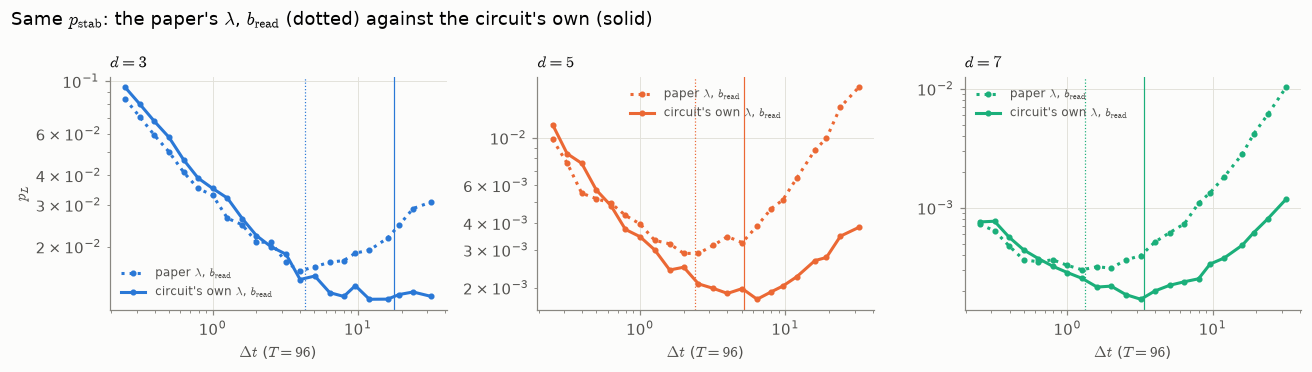

In [4]:
fig, axes = plt.subplots(1, len(ef["curves"]), figsize=(4 * len(ef["curves"]), 3.4), sharey=False)
for ax, c in zip(np.atleast_1d(axes), ef["curves"]):
    col = P.D_COLOR[c["d"]]
    for key, ls, lab in (("paper", ":", r"paper $\lambda$, $b_{\rm read}$"),
                         ("effective", "-", r"circuit's own $\lambda$, $b_{\rm read}$")):
        pts = c[key]["points"]
        ax.plot([p["dt"] for p in pts], [p["pL"] for p in pts], ls, marker="o", ms=3, color=col, label=lab)
        ax.axvline(c[key]["optimum"]["dt_star"], color=col, ls=ls, lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(P.dl(c["d"]), loc="left")
    ax.set_xlabel(r"$\Delta t$ ($T = 96$)"); ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel(P.PL)
fig.suptitle(r"Same $p_{\rm stab}$: the paper's $\lambda$, $b_{\rm read}$ (dotted) against the circuit's own (solid)", x=0.01, ha="left")
fig.tight_layout()
P.save(fig, "06a_artificial_idle_effective_parameters_2")

**Reading.**
- *Measured:* with only single-qubit noise (ρ = 0), the circuit's effective λ is well below the
  paper's 0.31: an extraction round already charges each data qubit several gate-errors' worth,
  so one idle op is small in comparison. λ falls further as ρ grows.
- *Measured:* b_read (solid) includes the 2×10⁻³ readout error and so sits well above 1 at these
  small gate rates; its floor (dashed, readout error off: what the ancilla's gate noise alone
  adds, the original repo's definition) is the circuit-structure part. Both fall as two-qubit
  noise grows, because the data error grows faster than the record error.
- *Measured:* those parameters move Δt*: with the circuit's own λ and b_read the optimum is
  2.2× (d = 5) and 2.5× (d = 7) longer than with the paper's, exactly the λ ratio Eq. 6 predicts
  (Δt* ∝ 1/λ: 0.31/0.131, 0.31/0.125); 4.1× at d = 3, where the readout term adds to it. Shots
  are sized per point to ~300 failures; with a fixed 100k shots the d = 7 curves (20–90
  failures per point) could not locate the minimum. The paper's two numbers are circuit
  properties to be measured, not constants; that is what notebook 06 does with realistic noise.
- *Why the next step:* this idle model (depolarizing, an op count with no duration) is not
  trapped-ion physics; notebook 07 replaces it with time-based Z dephasing on every qubit.